<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">🎮 Challenge 3 · CLIP Pictionary</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can you describe a photo so well that CLIP picks it out of 36?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/03_multimodal/02_challenge_clip_pictionary/Challenge_3_CLIP_Pictionary.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#challenge-3)

In notebook 05 you saw that **CLIP** puts photos and sentences in the **same vector space**: a good caption lands right next to its photo. Today you play *Pictionary* with it. You get a **secret photo**; you describe it with words; CLIP turns your words into a vector and ranks the 36 photos of the table from closest to farthest. The higher your secret photo, the more points you score.

## 🎯 Objectives
By the end of this challenge you will be able to:
- explain how a text→image search works with embeddings and cosine similarity (no training, no labels);
- write **distinctive** descriptions: what makes *this* photo different from its 35 neighbours;
- see what CLIP understands (colours, poses, scenes, synonyms) and where it struggles;
- chain two models: **speech → text** (Whisper) **→ image search** (CLIP).

**📋 Prerequisites:** notebook [05 · Everything is a vector](../01_project_everything_is_a_vector/05_Everything_Is_A_Vector.ipynb) · **▶️ How to use:** run all cells once (`Run All`), then edit the ✏️ **YOUR TURN** cells of each level and re-run them. You play alone: your score is yours.

## 🎮 How to play

> **You describe, CLIP guesses.** Each level shows you a **secret photo** from the table of 36 (our own pets + photos from notebook 04). Write up to **3 descriptions**; only your **best** one counts.
> For each description CLIP ranks all 36 photos by cosine similarity with your words.
>
> | Rank of your secret photo | Points |
> |---|---|
> | **#1** | **10** |
> | #2 – #3 | 5 |
> | #4 – #5 | 2 |
> | #6 or lower | 0 |
> | **Short bonus:** #1 with **5 words or fewer** | **+3** |
>
> **Level 1 · Easy** 🟢 a photo that stands out · **Level 2 · Look-alikes** 🟡 the table has several similar animals: find the detail that makes the difference · **Level 3 · Forbidden words** 🔴 describe it **without** *cat, dog, kitten, puppy, pet…* (a forbidden word = 0 points for that try) · **🎤 Voice bonus:** say your description out loud (a WAV file); Whisper writes it down and CLIP searches: **+5** if the secret photo is in the top 3.
>
> **Medals:** 🥉 Bronze ≥ 12 · 🥈 Silver ≥ 24 · 🥇 Gold ≥ 35 points. The example tries are worth a Silver: **beat them!**

## 📑 Contents
1. [🧠 How CLIP guesses](#sec-1)
2. [🟢 Level 1 · Easy](#sec-2)
3. [🟡 Level 2 · Look-alikes](#sec-3)
4. [🔴 Level 3 · Forbidden words](#sec-4)
5. [🎤 Voice bonus](#sec-5)
6. [🏆 Your scorecard](#sec-6)
7. [🧠 What did we learn?](#sec-7)
8. [📌 Summary](#sec-8)
9. [📚 Learn more](#sec-9)

<a id="sec-0"></a>
## ⚙️ Setup
CLIP (≈ 600 MB) and Whisper-tiny (≈ 150 MB) download on the first run, into the Hugging Face cache (already there if you ran notebook 05). Everything then runs on a laptop CPU in about a minute.

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa", "soundfile"], check=True)
    os.chdir(ROOT)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore")

print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import Audio
from IPython.display import Image as IPyImage
from IPython.display import display

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

from src import challenges as ch
from src import multimodal as mm
from src.paths import data_dir
from src.plotting import PALETTE, apply_style

apply_style()
SEED = 42
DATA = data_dir()
RULES = ch.CH3_RULES

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        from src.vision import save_slide_image
        save_slide_image(fig, ROOT / "assets" / "slides" / name)


def show_photos(fig):
    """Show a figure full of photos as a JPEG (keeps the notebook light) instead of a heavy PNG."""
    import io
    buf = io.BytesIO()
    fig.savefig(buf, format="jpg", dpi=80, pil_kwargs={"quality": 82})
    plt.close(fig)
    display(IPyImage(buf.getvalue()))

print("Ready · CPU is enough for this challenge")

Ready · CPU is enough for this challenge


<a id="sec-1"></a>
# 1. 🧠 How CLIP guesses

> 🧠 **How it works (recap of notebook 05)**
> 1. CLIP's **image encoder** turns each of the 36 photos into a vector of 512 numbers (once, at the start).
> 2. Its **text encoder** turns your description into a vector in the **same** space.
> 3. **Cosine similarity** between your vector and each photo vector → a score per photo → a **ranking**.
> - **Analogy:** a librarian who has read 400 million captioned photos. You describe a picture, she walks to the shelf where pictures *like that* live.
> - **Limits:** a vague description (*"a cat"*) is close to **every** cat; CLIP is weak at counting, at left/right, and at negation (*"not a dog"* often brings dogs!).

The table: our **17 pets** + **19 photos** from notebook 04's validation set, in a fixed shuffled order.

36 photos → 512 numbers each, in 10 s (CLIP loaded included)


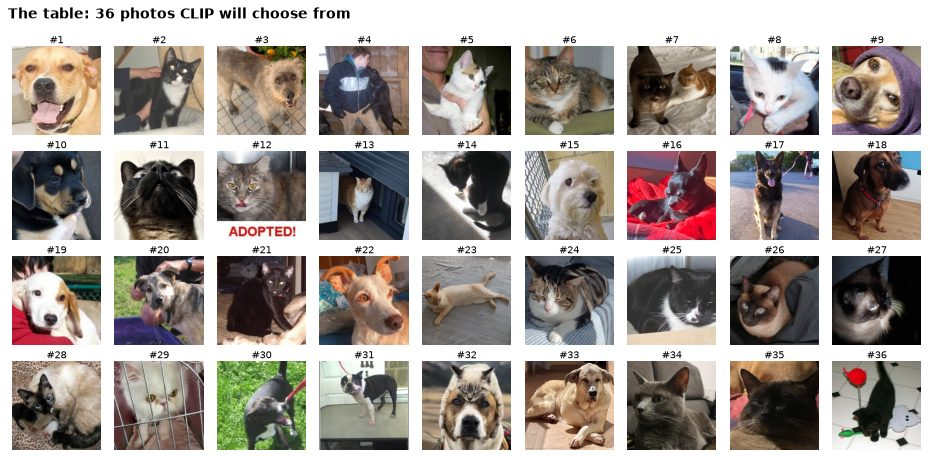

In [3]:
pets = sorted((DATA / "pets" / "cropped" / "cats").glob("*.jpg")) + sorted((DATA / "pets" / "cropped" / "dogs").glob("*.jpg"))
others = ([DATA / "cats_and_dogs" / "validation" / "cats" / f"cat.{i}.jpg" for i in range(2000, 2010)]
          + [DATA / "cats_and_dogs" / "validation" / "dogs" / f"dog.{i}.jpg" for i in range(2000, 2009)])
order = np.random.default_rng(3).permutation(len(pets) + len(others))    # fixed order: same table for everybody
POOL = [(pets + others)[i] for i in order]
NAMES = [p.stem for p in POOL]

t0 = time.perf_counter()
POOL_VECS = mm.clip_embed_images(POOL)
print(f"{len(POOL)} photos → {POOL_VECS.shape[1]} numbers each, in {time.perf_counter() - t0:.0f} s (CLIP loaded included)")
fig = ch.plot_numbered_grid(POOL, ncols=9, title="The table: 36 photos CLIP will choose from")
show_photos(fig)

In [4]:
SECRETS = {"Level 1": "cat10000", "Level 2": "cat9005", "Level 3": "dog9016AI", "Voice": "dog9007"}
results = {}   # best try of each level


def show_secret(level):
    """Show the secret photo of a level (big) with its number on the table."""
    k = NAMES.index(SECRETS[level])
    fig, ax = plt.subplots(figsize=(3.2, 3.4))
    ax.imshow(ch.thumbnail(POOL[k], 320))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(PALETTE["orange"]); sp.set_linewidth(5)
    ax.set_title(f"{level} · your secret photo: #{k + 1}", fontsize=12, loc="center")
    show_photos(fig)


def play(level, tries, forbidden=(), voice=False):
    """Rank the table for each description, score it, show CLIP's top 5 and keep the best try."""
    target = NAMES.index(SECRETS[level])
    results.pop(level, None)                                  # a re-run always starts this level from 0
    tries = ch.clean_entries([t for t in tries if isinstance(t, str)], RULES["max_tries"])
    if not tries:
        print(f"✏️ {level}: no description yet (empty or blank). Write at least one, then re-run. {level} = 0 points.")
        return None
    long = [t for t in tries if ch.word_count(t) > ch.MAX_DESCRIPTION_WORDS]
    if long:
        print(f"✂️ CLIP reads about {ch.MAX_DESCRIPTION_WORDS} words at most: long descriptions are cut there.")
    tries = [ch.first_words(t, ch.MAX_DESCRIPTION_WORDS) for t in tries]
    scores = mm.cosine_similarity(mm.clip_embed_texts(tries), POOL_VECS)
    attempts = []
    for text, s in zip(tries, scores):
        rank = ch.rank_of(target, s)
        if voice:
            pts = {"points": 0, "bonus": RULES["voice_bonus_top3"] if rank <= 3 else 0, "foul": False}
            pts["total"] = pts["bonus"]
        else:
            pts = ch.pictionary_points(rank, ch.word_count(text), ch.forbidden_used(text, forbidden))
        attempts.append({"text": text, "scores": s, "rank": rank, **pts})
    best = ch.best_try(attempts)
    results[level] = best
    title = (f"{level}: best try puts the secret photo at #{best['rank']} → +{best['total']} points"
             if not best["foul"] else f"{level}: every try used a forbidden word → 0 points")
    fig = ch.plot_tries(POOL, target, attempts, title=title)
    show_photos(fig)
    return fig

<a id="sec-2"></a>
# 2. 🟢 Level 1 · Easy

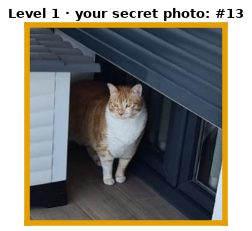

In [5]:
show_secret("Level 1")

### ✏️ YOUR TURN · Level 1
Up to 3 descriptions; the best one counts. Tip: what would you say to a friend so they find **this** photo on the table?

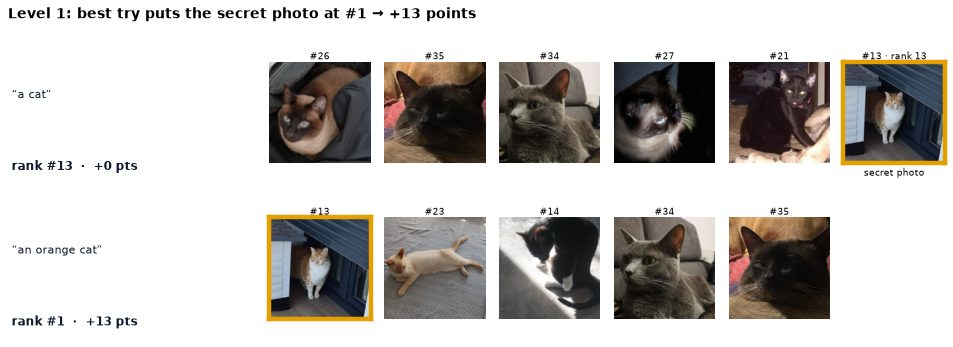

In [6]:
# ✏️ YOUR TURN: up to 3 descriptions of the secret photo
LEVEL_1 = [
    "a cat",
    "an orange cat",
]
fig = play("Level 1", LEVEL_1)

👀 **What to notice:** *"a cat"* is close to **every** cat on the table, so the secret photo is lost in the middle. One well-chosen word (*orange*) is enough to jump to #1: CLIP is not matching the word "cat", it is matching the **whole meaning** of the sentence to the whole photo.

<a id="sec-3"></a>
# 3. 🟡 Level 2 · Look-alikes
The table has several dark Siamese-type cats. Find what makes **this one** different: the background, the pose, the colours, the light…

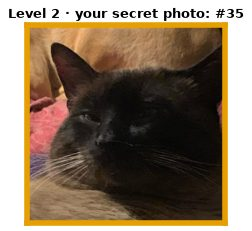

In [7]:
show_secret("Level 2")

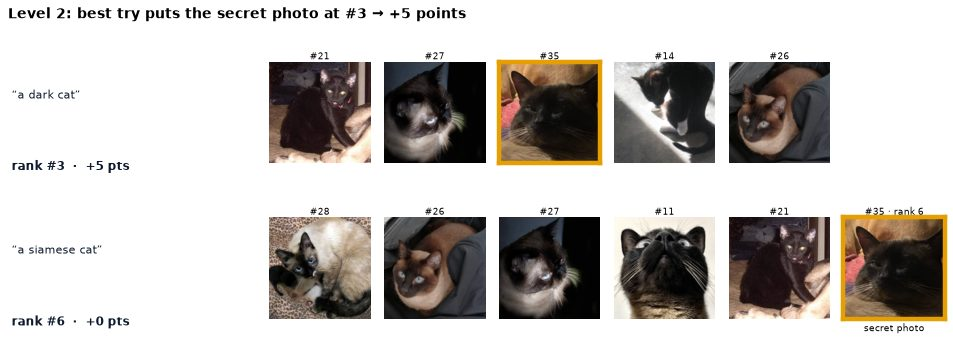

In [8]:
# ✏️ YOUR TURN: up to 3 descriptions of the secret photo
LEVEL_2 = [
    "a dark cat",
    "a siamese cat",
]
fig = play("Level 2", LEVEL_2)

<a id="sec-4"></a>
# 4. 🔴 Level 3 · Forbidden words
Describe the secret photo **without** any of these words (a forbidden word = 0 points for that try):

🚫 cat, cats, kitten, kittens, kitty, kitties, dog, dogs, puppy, puppies, pup, pups, doggy, doggie, pet, pets, feline, canine


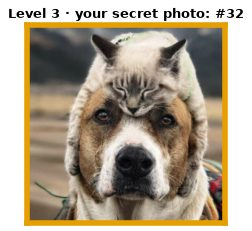

In [9]:
FORBIDDEN = ch.FORBIDDEN_WORDS
print("🚫", ", ".join(FORBIDDEN))
show_secret("Level 3")

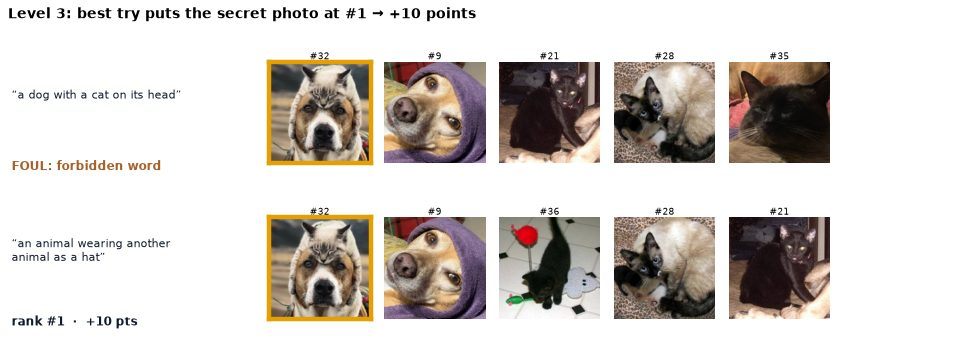

In [10]:
# ✏️ YOUR TURN: up to 3 descriptions, without the forbidden words
LEVEL_3 = [
    "a dog with a cat on its head",
    "an animal wearing another animal as a hat",
]
fig = play("Level 3", LEVEL_3, forbidden=FORBIDDEN)
if fig is not None:
    save_slide(fig, "ch3-pictionary.webp")

👀 **What to notice:** the first try was the obvious description, but it used forbidden words. Without them, *"an animal wearing another animal as a hat"* still works: CLIP understands **descriptions and synonyms**, not just keywords. Remember the keyword search of notebook 05: it would have found nothing.

<a id="sec-5"></a>
# 5. 🎤 Voice bonus

Two models in a chain: **Whisper** (speech → text, notebook 05) and **CLIP** (text → photo). The example WAV describes the secret photo below; replace it with your own recording.

**Your own voice:** record yourself with your phone or laptop, save as **WAV** (or FLAC/OGG), put it in `data/audio/` and change `VOICE_FILE`. In Colab, set `UPLOAD_WAV = True` to upload it. (Phone apps often save `.m4a`: convert it to WAV first, e.g. with Audacity.)

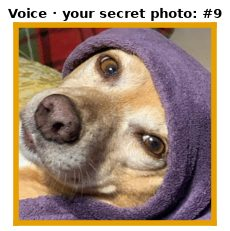

In [11]:
show_secret("Voice")

🎤 Whisper heard (2.4 s): “A dog wrapped in a purple blanket, looking up at the camera.”


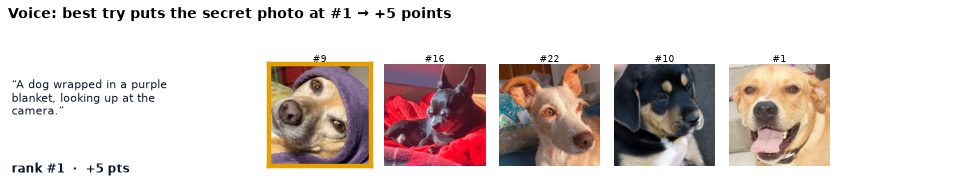

In [12]:
# ✏️ YOUR TURN: your own recording
VOICE_FILE = DATA / "audio" / "pictionary_purple_blanket.wav"
UPLOAD_WAV = False                         # Colab: True = upload a WAV from your computer

if IN_COLAB and UPLOAD_WAV:
    from google.colab import files
    uploaded = files.upload() or {}
    if uploaded:
        name, content = next(iter(uploaded.items()))
        VOICE_FILE = DATA / "audio" / name
        VOICE_FILE.write_bytes(content)
    else:
        print("No file uploaded: using", VOICE_FILE.name)

display(Audio(str(VOICE_FILE)))
t0 = time.perf_counter()
heard = mm.transcribe(VOICE_FILE)
print(f"🎤 Whisper heard ({time.perf_counter() - t0:.1f} s): “{heard}”")
if not heard.strip():
    print("🔇 Whisper heard nothing (silence or a very short recording?). Voice bonus = 0: try another recording.")
fig = play("Voice", [heard], voice=True)

<a id="sec-6"></a>
# 6. 🏆 Your scorecard

,level,best try,rank,points
0,Level 1,an orange cat,1,13
1,Level 2,a dark cat,3,5
2,Level 3,an animal wearing another animal as a hat,1,10
3,Voice,"A dog wrapped in a purple blanket, looking up ...",1,5


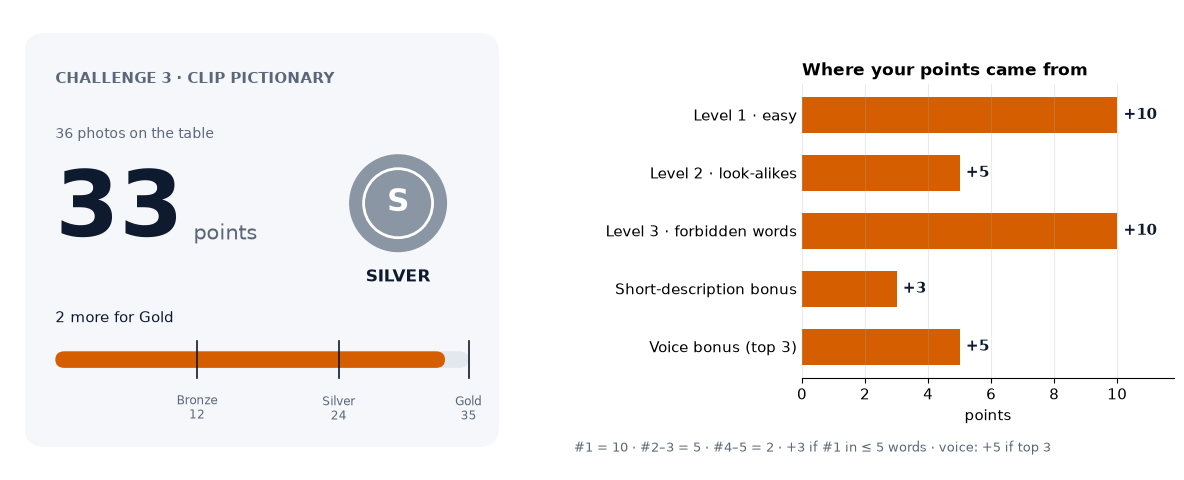

🥈 Silver: 33 points. 2 more for Gold!


In [13]:
labels = {"Level 1": "Level 1 · easy", "Level 2": "Level 2 · look-alikes", "Level 3": "Level 3 · forbidden words"}
breakdown = {labels[k]: results[k]["points"] for k in labels if k in results}
breakdown["Short-description bonus"] = sum(results[k]["bonus"] for k in labels if k in results)
breakdown["Voice bonus (top 3)"] = results["Voice"]["total"] if "Voice" in results else 0
total = sum(breakdown.values())
medal, nxt, missing = ch.medal_for(total, ch.LEVELS["clip_pictionary"])
display(pd.DataFrame([{"level": k, "best try": r["text"], "rank": r["rank"], "points": r["total"]}
                      for k, r in results.items()]))
fig = ch.plot_scorecard(total, breakdown, ch.LEVELS["clip_pictionary"], "Challenge 3 · CLIP Pictionary",
                        subtitle=f"{len(POOL)} photos on the table", accent=PALETTE["red"],
                        footnote="#1 = 10 · #2–3 = 5 · #4–5 = 2 · +3 if #1 in ≤ 5 words · voice: +5 if top 3")
save_slide(fig, "ch3-scorecard.png")
plt.show()
print(f"{ch.MEDAL_EMOJI[medal]} {medal}: {total} points." + (f" {missing} more for {nxt}!" if nxt else " Top level!"))

<a id="sec-7"></a>
# 7. 🧠 What did we learn?

| What happened in the game | The idea behind it | Back to |
|---|---|---|
| CLIP found photos from **sentences**, with no training and no labels | text and images share **one vector space**; search = nearest vectors (cosine) | notebook 05 · CLIP |
| *"a cat"* failed, *"an orange cat"* won | a vague vector is close to many photos; **distinctive** details move it next to one | notebook 05 · semantic search |
| Look-alikes needed the **background or pose** | CLIP encodes the whole scene, not only the animal | notebook 04 · Grad-CAM (where the model looks) |
| Forbidden words did not stop you | embeddings capture **meaning**, so synonyms and paraphrases land in the same place | notebook 05 · keyword vs semantic search |
| Speech → text → photo worked | models can be **chained** through text: Whisper's output is CLIP's input | notebook 05 · Whisper |

## 💬 Discussion
1. Try *"a photo with no dog"* on Level 3. Where does the secret photo land? Why is negation hard for CLIP?
2. A shop wants "search our catalogue with your own words". What would you build, and what could go wrong?
3. Your short descriptions often beat long ones. Is longer always better for a search engine?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

1. *"no dog"* still contains the concept *dog*, so its vector moves **towards** dogs. CLIP learned from captions, and people rarely describe what is *not* in a photo. Same family of blind spot as the bag of words in Challenge 1 (the word is there, the meaning is the opposite).
2. Exactly this game: embed every product photo once with CLIP, embed the query, return the nearest. Risks: biased or wrong matches (CLIP learned from the web), products with little visual difference, queries in other languages (multilingual CLIP models exist), and evaluating it needs real user queries.
3. No: CLIP's text encoder reads at most 77 tokens and gives every word some weight; extra generic words (*"a nice photo of a lovely…"*) dilute the distinctive ones. Precise beats long, the same lesson as good search queries.
</details>

<a id="sec-8"></a>
# 8. 📌 Summary

| Idea | In one line |
|---|---|
| Shared space | CLIP puts photos and sentences in one 512-number space |
| Text → image search | Embed the query, rank the photos by cosine similarity |
| Distinctive details | The best description is the one that separates *this* photo from its neighbours |
| Meaning, not keywords | Synonyms and paraphrases work: that is what embeddings are for |
| Model chains | Speech → (Whisper) → text → (CLIP) → photo |

**✅ Checklist:**
- [ ] I got a secret photo to #1 in at least one level.
- [ ] I can explain why *"a cat"* ranks badly on this table.
- [ ] I described a photo without its obvious keywords.
- [ ] I tried the voice bonus (example or my own recording).

<a id="sec-9"></a>
# 9. 📚 Learn more

> 📚 **Learn more**
> - Radford et al. (2021). [*Learning Transferable Visual Models From Natural Language Supervision*](https://arxiv.org/abs/2103.00020) (the CLIP paper) · model card of [`openai/clip-vit-base-patch32`](https://huggingface.co/openai/clip-vit-base-patch32)
> - Radford et al. (2022). [*Robust Speech Recognition via Large-Scale Weak Supervision*](https://arxiv.org/abs/2212.04356) (Whisper) · [`openai/whisper-tiny`](https://huggingface.co/openai/whisper-tiny)
> - Hugging Face docs: [CLIP in 🤗 Transformers](https://huggingface.co/docs/transformers/model_doc/clip)
> - Yuksekgonul et al. (2023). [*When and why vision-language models behave like bags-of-words*](https://arxiv.org/abs/2210.01936): why CLIP mixes up word order and negation.

---
<div align="center">

⬅️ [Previous: 05 · Everything is a vector](../01_project_everything_is_a_vector/05_Everything_Is_A_Vector.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Back to the Lesson 03 overview](../../README.md) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>